<a href="https://colab.research.google.com/github/James007Bond-code/BLM5103-Proje1-Grup03/blob/main/BIL545_Proje1_Beijing_PM25_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIL545 · Proje 1 · Beijing PM2.5 kirlilik epizotları

**Grup adı:** Grup 03
**Üyeler:** Süleyman Balsak (254312022) · Seda Erten (254312008) · İlkin Urcan (244329078) · Aslıhan Semiz Varlı (254329024)
**İletişim sorumlusu:** Süleyman Balsak
**Konu:** 9.7 Hava kalitesi ve kirlilik epizotları · **Veri:** UCI Beijing PM2.5 (PRSA, 2010–2014, saatlik)

## 0. Hazırlık

In [1]:
# Gerekli ek kütüphane (birliktelik analizi için)
!pip install -q mlxtend

import sys
import warnings
import numpy as np
import pandas as pd
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt
import mlxtend

from scipy import stats
from scipy.stats import binomtest, chi2
from sklearn.base import clone
from sklearn.model_selection import (TimeSeriesSplit, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Kütüphane sürümleri (yönerge 3.3)
print("=== KÜTÜPHANE SÜRÜMLERİ ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"mlxtend      : {mlxtend.__version__}")

# 2. Rastgelelik tohumu (tekrarlanabilirlik)
SEED = 42
np.random.seed(SEED)
print("\nRastgelelik tohumu (SEED) 42 olarak sabitlendi.")

=== KÜTÜPHANE SÜRÜMLERİ ===
Python       : 3.13.18
Pandas       : 2.2.3
NumPy        : 2.4.6
Scikit-learn : 1.6.1
SciPy        : 1.16.3
Matplotlib   : 3.10.0
mlxtend      : 0.23.4

Rastgelelik tohumu (SEED) 42 olarak sabitlendi.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Okuma notları
- **Kaufman vd. (2012), Leakage in data mining:** Sızıntıyı, tahmin anında bilinemeyecek bilginin modele ya da değerlendirmeye karışması olarak tanımlıyor ve iki kaynağını ayırıyor: hedeften türetilmiş ya da sonradan bilinen öznitelikler, ve eğitim ile test örnekleri arasındaki bağımlılık. Önerdikleri çözüm, her öznitelik ve kayıt için "tahmin anında ne biliniyor?" sorusunu baştan tanımlamak. Bu veride ilk tür `pm2.5` sütunudur (hedefin kaynağı, girdiden çıkarıldı); ikinci tür ise ardışık saatlerin karıştırılmış bölmede eğitim ve teste dağılmasıdır (1.7'de ölçüldü).
- **Dietterich (1998), Approximate statistical tests:** Beş testi benzetimle karşılaştırıyor. Yeniden örneklenmiş t-testi ile k katlı CV üzerinde eşleştirilmiş t-testinin I. tip hatası yüksek çıkıyor, çünkü kat skorlarının eğitim kümeleri örtüşüyor ve bağımsız değiller. Öneri: tek bir test kümesi ayrılabiliyorsa McNemar, birkaç kez eğitim mümkünse 5×2 cv t-testi. Veriyi karıştıramadığımız için (zaman serisi) 5×2 cv yerine dokunulmayan zamansal test kümesinde McNemar kullandık.
- **Wu, Chen ve Han (2010), Interestingness measures:** Lift ve χ², kuralla ilgisi olmayan "null" işlemlerin sayısından etkileniyor, yani null-invariant değiller. All-confidence, max-confidence, Kulczynski ve cosine ölçütlerini tek bir genelleştirilmiş ortalama çerçevesinde topluyorlar ve Kulczynski'yi dengesizlik oranıyla (IR) birlikte kullanmayı öneriyorlar: Kulczynski ≈ 0,5 değeri ancak IR ile birlikte okunduğunda "nötr" mü "dengesiz" mi anlaşılabiliyor. 3.2'deki sıralamalar bu öneriye göre yapıldı.

In [2]:
# UCI Beijing PM2.5 verisini kaynaktan doğrudan çekme
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00381/PRSA_data_2010.1.1-2014.12.31.csv"
df = pd.read_csv(url)

print(f"Veri boyutu: {df.shape[0]} satır, {df.shape[1]} sütun.")
df.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Veri boyutu: 43824 satır, 13 sütun.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Bölüm 1 · Veri, ön işleme ve sızıntı

### 1.1 Veri künyesi
- **Kim, hangi amaçla topladı:** Liang vd. (2015), Pekin'deki PM2.5 kirliliğinin şiddetini ve hava koşullarıyla ilişkisini incelemek için iki kaynağı birleştirdi: PM2.5 ölçümleri ABD Büyükelçiliği'nin izleme istasyonundan, meteoroloji ölçümleri Pekin Başkent Uluslararası Havalimanı'ndan geliyor. Veri UCI Machine Learning Repository'de yayımlandı.
- **Dönem:** 1 Ocak 2010 – 31 Aralık 2014, saatlik (43.824 kayıt).
- **Hedef gerçek olgu mu, vekil mi:** Vekil. (1) Tek bir istasyonun ölçümü bütün şehrin kirliliği yerine kullanılıyor. (2) "Epizot", saatlik değere uygulanan 75 µg/m³ eşiğiyle tanımlandı; bu eşik aslında 24 saatlik ortalama için konmuş bir standart. (3) Hava koşulları PM2.5 istasyonunda değil, şehrin başka bir noktasındaki havalimanında ölçülüyor.
- **Kimler eksik temsil ediliyor olabilir:** İstasyonun bulunduğu merkezî bölge dışındaki semtler ve kırsal çevre; iç mekân maruziyeti. Zamansal olarak da 2010–2012'deki uzun ölçüm boşlukları (1.3) o dönemleri eksik temsil ediyor.
- **Lisans:** CC BY 4.0 (UCI).

In [3]:
ham = df.drop(columns=['No'])
eda = pd.DataFrame({
    'tip': ham.dtypes.astype(str),
    'olcek': ['aralık (yıl)', 'sıralı/döngüsel', 'sıralı/döngüsel', 'sıralı/döngüsel', 'oran (µg/m³)',
              'aralık (°C)', 'aralık (°C)', 'oran (hPa)', 'nominal', 'oran (m/s, birikimli)',
              'oran (saat, birikimli)', 'oran (saat, birikimli)'],
    'eksik_%': (ham.isna().mean() * 100).round(2),
    'farkli_deger': ham.nunique(),
    'sifir_%': (ham.apply(lambda s: (s == 0).mean() if s.dtype.kind in 'if' else 0.0) * 100).round(2),
})
display(eda)

print("Yinelenen satır (bütün sütunlar)          :", ham.duplicated().sum())
print("Yinelenen zaman damgası (yıl-ay-gün-saat) :", ham.duplicated(subset=['year', 'month', 'day', 'hour']).sum())
print("Hedef hariç aynı olan satır               :", ham.drop(columns=['pm2.5']).duplicated().sum())

# Şüpheli öznitelikler:
#  - No: satır numarası (kimlik benzeri) → çıkarılacak
#  - pm2.5: hedefin kaynağı → girdiden çıkarılacak
#  - year: zamana göre bölmede test yılı eğitimde hiç görülmez; ağaçlar dışa değer tahmini yapamaz
#  - day: ayın günü, fiziksel bir anlamı yok
#  - Iws / Is / Ir: birikimli değişkenler (aynı koşulun kaç saattir sürdüğü)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,tip,olcek,eksik_%,farkli_deger,sifir_%
year,int64,aralık (yıl),0.00,5,0.00
month,int64,sıralı/döngüsel,0.00,12,0.00
day,int64,sıralı/döngüsel,0.00,31,0.00
hour,int64,sıralı/döngüsel,0.00,24,4.17
pm2.5,float64,oran (µg/m³),4.72,581,0.00
DEWP,int64,aralık (°C),0.00,69,1.90
TEMP,float64,aralık (°C),0.00,64,2.59
PRES,float64,oran (hPa),0.00,60,0.00
cbwd,object,nominal,0.00,4,0.00
Iws,float64,"oran (m/s, birikimli)",0.00,2788,0.00


Yinelenen satır (bütün sütunlar)          : 0
Yinelenen zaman damgası (yıl-ay-gün-saat) : 0
Hedef hariç aynı olan satır               : 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** Veride 43.824 saatlik kayıt ve 12 sütun var (No hariç). Yinelenen satır ya da yinelenen zaman damgası yok; her saat bir kez kaydedilmiş. Eksik değer yalnızca hedefte (`pm2.5`, %4,72). Sıfır oranları kodlanmış eksik değer işareti taşımıyor: `hour` için %4,17 = 1/24 (gece yarısı), `DEWP` ve `TEMP` için 0 °C fiziksel bir değer. `Is` (%99,2) ve `Ir` (%95,9) ise neredeyse hep sıfır; kar ve yağmur nadir olduğu için bilgi taşıma kapasiteleri düşük.

Şüpheli öznitelikler: `No` satır numarasıdır (kimlik benzeri), çıkarıldı. `pm2.5` hedefin kaynağıdır, girdiden çıkarıldı. `year` zamana göre bölmede test yılını eğitimde hiç görmez; `day` (ayın günü) fiziksel bir anlam taşımaz. Bu ikisi Proje 1'de tutuldu ve etkileri ölçüldü: Ek paket 1'de permütasyon önemleri `year` için 0,000, `day` için 0,003 çıktı. Weka J48 ağacı ise bu iki sütunu belirli dönemleri ezberlemek için kullandı (1.7). Bu yüzden Proje 2'de çıkarılmaya adaydırlar.

### 1.3 Eksiklik analizi

In [4]:
eksik = df['pm2.5'].isna()
print(f"pm2.5 eksik: {eksik.sum()} satır (%{eksik.mean()*100:.2f})")
print("Diğer sütunlardaki toplam eksik:", int(df.drop(columns=['pm2.5']).isna().sum().sum()))
# Bu veride eksikler NaN olarak geliyor; -999 gibi kodlanmış eksik yok (yukarıdaki tablo ile doğrulayın).

# 1) Zaman deseni: yıl × ay eksik oranı (%)
print("\nYıl × ay eksik oranı (%)")
display((df.assign(eksik=eksik)
           .pivot_table(index='year', columns='month', values='eksik', aggfunc='mean') * 100).round(1))

# 2) Eksikler ardışık bloklar hâlinde mi? (cihaz arızası → uzun bloklar; rastgele → tek tek saatler)
blok_id = (eksik != eksik.shift()).cumsum()
bloklar = eksik[eksik].groupby(blok_id[eksik]).size()
print(f"Eksik blok sayısı: {len(bloklar)} · medyan uzunluk: {bloklar.median():.0f} saat · "
      f"en uzun: {bloklar.max()} saat · 24 saatten uzun blok: {(bloklar > 24).sum()}")

# 3) MAR mı? Eksik saatlerde hava koşulları farklı mı?
print("\nHava değişkenlerinin ortalaması: pm2.5 var / eksik")
display(df.groupby(eksik)[['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']].mean()
          .rename(index={False: 'pm2.5 var', True: 'pm2.5 eksik'}).round(2))
display(pd.crosstab(eksik.map({False: 'pm2.5 var', True: 'pm2.5 eksik'}), df['cbwd'], normalize='index').round(3))

pm2.5 eksik: 2067 satır (%4.72)
Diğer sütunlardaki toplam eksik: 0

Yıl × ay eksik oranı (%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2010,12.2,0.1,4.7,0.3,0.9,21.5,0.0,9.1,35.0,0.3,7.8,0.0
2011,9.7,0.0,16.0,25.6,4.3,1.2,0.4,23.4,0.1,17.2,0.7,0.1
2012,9.9,0.9,0.5,0.1,7.1,1.7,7.5,16.3,0.8,0.5,3.1,17.5
2013,0.7,0.1,0.7,0.7,2.3,0.3,0.9,1.2,0.4,0.8,0.3,2.7
2014,0.9,0.4,0.1,0.4,0.3,2.4,0.9,1.5,0.7,0.1,1.9,3.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Eksik blok sayısı: 214 · medyan uzunluk: 1 saat · en uzun: 155 saat · 24 saatten uzun blok: 20

Hava değişkenlerinin ortalaması: pm2.5 var / eksik


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,DEWP,TEMP,PRES,Iws,Is,Ir
pm2.5,,,,,,
pm2.5 var,1.75,12.4,1016.44,23.87,0.06,0.19
pm2.5 eksik,3.17,13.4,1016.54,24.34,0.00,0.20


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


cbwd,NE,NW,SE,cv
pm2.5,,,,
pm2.5 eksik,0.117,0.322,0.347,0.214
pm2.5 var,0.114,0.323,0.349,0.214


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** Eksiklik yalnızca hedefte: `pm2.5`'te 2.067 saat (%4,72) eksik, diğer sütunlarda hiç eksik yok. Bu yüzden yönergedeki "en çok eksiği olan iki sütun" bu veride tek bir sütuna karşılık geliyor.

- **Desen:** Eksikler 2010–2012'de yoğun (2010 Eylül %35,0; 2011 Nisan %25,6; 2010 Haziran %21,5), 2013–2014'te hiçbir ayda %3,8'i geçmiyor. 214 eksik bloğun medyan uzunluğu 1 saat (tek tük boşluklar), ama 20 blok 24 saatten uzun ve en uzunu 155 saat (yaklaşık 6,5 gün). Bu tablo ölçüm cihazındaki arıza ve bakım dönemlerine işaret ediyor.
- **Mekanizma tahmini:** Eksik ve dolu saatlerde hava koşulları çok benzer: rüzgâr yönü payları neredeyse aynı (SE %34,7 / %34,9; NW %32,2 / %32,3), sıcaklık ve çiy noktası farkları 1–1,5 °C. Yani eksiklik gözlenen hava değişkenlerine bağlı görünmüyor. Ama döneme (yıla) bağlı olduğu için tam MCAR değil, **yıla göre MAR** demek daha doğru. MNAR ihtimali (örn. çok yüksek kirlilikte cihazın ölçüm yapamaması) eksik değerin kendisini görmeden sınanamaz; bunu söyleyemeyiz.
- **Karar:** Hedef doldurulamayacağı için eksik satırlar çıkarıldı (41.757 satır kaldı). Eksiklik hava koşullarından bağımsız göründüğü için bunun ciddi bir yanlılık yaratması beklenmiyor, ama 2010–2012 dönemleri bir miktar eksik temsil ediliyor. Özniteliklerde eksik olmadığı için `add_indicator` etkisiz; bu 1.5'te gösterildi (eklenen gösterge sütunu: 0, F1 değişmedi).

### 1.4 Temizleme ve hedef

In [5]:
# 1. Ham verinin kopyası
df_clean = df.copy()

# 2. 'No' kimlik sütununu kaldırma (Kaufman vd., 2012: kimlik benzeri sütunlar)
df_clean = df_clean.drop(columns=['No'])

# 3. Yıl, ay, gün, saati tek bir datetime sütununa dönüştürme ve sıralama
df_clean['datetime'] = pd.to_datetime(df_clean[['year', 'month', 'day', 'hour']])
df_clean = df_clean.sort_values('datetime').reset_index(drop=True)

# 4. Hedefi eksik satırları çıkarma
print(f"Ham veri satır sayısı: {len(df_clean)}")
df_clean = df_clean.dropna(subset=['pm2.5']).reset_index(drop=True)
print(f"Hedefi dolu satır sayısı: {len(df_clean)}")

# 5. PM2.5'i ikili sınıfa çevirme: epizot = PM2.5 > 75 µg/m³
#    75 µg/m³, Çin GB 3095-2012 standardının 24 saatlik II. sınıf sınırıdır.
#    Burada saatlik değere uygulanıyor (varsayım defterine yazıldı).
df_clean['kirlilik_epizodu'] = (df_clean['pm2.5'] > 75).astype(int)

# 6. Sınıf dağılımı
oranlar = df_clean['kirlilik_epizodu'].value_counts(normalize=True) * 100
print("\n--- Sınıf Dağılımı ---")
print(f"0 (Temiz Hava)      : %{oranlar[0]:.2f}")
print(f"1 (Kirlilik Epizodu): %{oranlar[1]:.2f}")

df_clean[['datetime', 'pm2.5', 'kirlilik_epizodu', 'TEMP', 'PRES', 'cbwd', 'Iws']].head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ham veri satır sayısı: 43824
Hedefi dolu satır sayısı: 41757

--- Sınıf Dağılımı ---
0 (Temiz Hava)      : %51.51
1 (Kirlilik Epizodu): %48.49


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,datetime,pm2.5,kirlilik_epizodu,TEMP,PRES,cbwd,Iws
0,2010-01-02 00:00:00,129.0,1,-4.0,1020.0,SE,1.79
1,2010-01-02 01:00:00,148.0,1,-4.0,1020.0,SE,2.68
2,2010-01-02 02:00:00,159.0,1,-5.0,1021.0,SE,3.57
3,2010-01-02 03:00:00,181.0,1,-5.0,1022.0,SE,5.36
4,2010-01-02 04:00:00,138.0,1,-5.0,1022.0,SE,6.25


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
# Girdilerden çıkarılacak sütunlar:
# - 'pm2.5': hedef bundan türetildi → modelde kalırsa doğrudan sızıntı
# - 'kirlilik_epizodu': hedef (y)
# - 'datetime': yalnızca sıralama için
# Tahmin anı: aynı saatin hava koşullarıyla aynı saatin epizodu (anlık tespit, erken uyarı değil).
drop_cols = ['datetime', 'pm2.5', 'kirlilik_epizodu']

X = df_clean.drop(columns=drop_cols)
y = df_clean['kirlilik_epizodu']

cat_cols = ['cbwd']                                   # rüzgâr yönü
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Öznitelik sayısı: {X.shape[1]}")
print("Sayısal sütunlar :", num_cols)
print("Kategorik sütun  :", cat_cols)

Öznitelik sayısı: 11
Sayısal sütunlar : ['year', 'month', 'day', 'hour', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
Kategorik sütun  : ['cbwd']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
# Dokunulmayan zamansal test kümesi: son %20.
# Model seçimi, ayar ve karşılaştırmalar yalnızca ilk %80'de (geliştirme) yapılır;
# son %20 yalnızca McNemar testi ve Ek paket 1'de bir kez kullanılır.
split_idx = int(len(X) * 0.8)
X_dev, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_dev, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 5 katlı zamana göre çapraz doğrulama. gap=24: eğitim katının sonu ile test katının başı
# arasında 24 saat boşluk. Ardışık saatler neredeyse aynı olduğu için sınırdan sızıntıyı önler.
tscv = TimeSeriesSplit(n_splits=5, gap=24)

print("Geliştirme:", df_clean['datetime'].iloc[0], "→", df_clean['datetime'].iloc[split_idx - 1], f"({len(X_dev)} saat)")
print("Test      :", df_clean['datetime'].iloc[split_idx], "→", df_clean['datetime'].iloc[-1], f"({len(X_test)} saat)")
print(f"Epizot oranı · geliştirme: %{y_dev.mean()*100:.1f} · test: %{y_test.mean()*100:.1f}")

Geliştirme: 2010-01-02 00:00:00 → 2014-01-14 01:00:00 (33405 saat)
Test      : 2014-01-14 02:00:00 → 2014-12-31 23:00:00 (8352 saat)
Epizot oranı · geliştirme: %48.7 · test: %47.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 1.5 Sızıntı deneyi, baseline ve ilk model

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== SIZINTI DENEYİ VE BASELINE (F1, pozitif sınıf: epizot) ===
Baseline (Dummy)                    : 0.1188 ± 0.2377
Lojistik regresyon · sızıntılı      : 0.6740 ± 0.1083
Lojistik regresyon · doğru (Pipeline): 0.6679 ± 0.1199


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


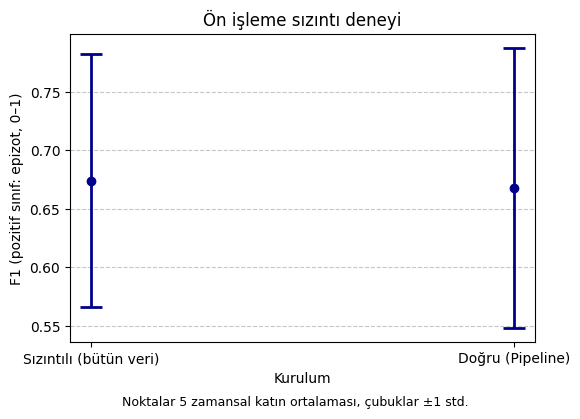

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [8]:
# -------------------------------------------------------------
# 1. DOĞRU KURULUM: ön işleme Pipeline içinde (her katta yalnız eğitim verisiyle fit)
# -------------------------------------------------------------
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

pipeline_dogru = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=SEED))
])
scores_dogru = cross_val_score(pipeline_dogru, X_dev, y_dev, cv=tscv, scoring='f1')

# Baseline: aynı sızıntısız hatta DummyClassifier
pipeline_dummy = Pipeline([('preprocessor', preprocessor),
                           ('classifier', DummyClassifier(strategy='most_frequent'))])
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # Dummy hiç pozitif tahmin etmediği için F1 = 0 uyarısı
    scores_dummy = cross_val_score(pipeline_dummy, X_dev, y_dev, cv=tscv, scoring='f1')

# -------------------------------------------------------------
# 2. HATALI KURULUM: ön işleme bütün geliştirme verisinde bir kez (sızıntılı)
# -------------------------------------------------------------
X_hatali = X_dev.copy()
num_imp = SimpleImputer(strategy='median').fit_transform(X_hatali[num_cols])
scaled = StandardScaler().fit_transform(num_imp)
cat_imp = SimpleImputer(strategy='most_frequent').fit_transform(X_hatali[cat_cols])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit_transform(cat_imp)
X_hatali_processed = np.hstack([scaled, ohe])

model_hatali = LogisticRegression(max_iter=1000, random_state=SEED)
scores_hatali = cross_val_score(model_hatali, X_hatali_processed, y_dev, cv=tscv, scoring='f1')

# -------------------------------------------------------------
# Sonuçlar (ortalama ± std)
# -------------------------------------------------------------
print("=== SIZINTI DENEYİ VE BASELINE (F1, pozitif sınıf: epizot) ===")
print(f"Baseline (Dummy)                    : {scores_dummy.mean():.4f} ± {scores_dummy.std():.4f}")
print(f"Lojistik regresyon · sızıntılı      : {scores_hatali.mean():.4f} ± {scores_hatali.std():.4f}")
print(f"Lojistik regresyon · doğru (Pipeline): {scores_dogru.mean():.4f} ± {scores_dogru.std():.4f}")

plt.figure(figsize=(6, 4))
plt.errorbar(
    ['Sızıntılı (bütün veri)', 'Doğru (Pipeline)'],
    [scores_hatali.mean(), scores_dogru.mean()],
    yerr=[scores_hatali.std(), scores_dogru.std()],
    fmt='o', capsize=8, capthick=2, elinewidth=2, color='darkblue'
)
plt.xlabel('Kurulum')
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.title('Ön işleme sızıntı deneyi')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.figtext(0.5, -0.05, 'Noktalar 5 zamansal katın ortalaması, çubuklar ±1 std.', ha='center', fontsize=9)
plt.show()

In [9]:
# add_indicator: eksikliğin kendisini öznitelik olarak eklemek (yönerge 4.1)
pre_ind = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', cat_transformer, cat_cols)
])
pipeline_ind = Pipeline([('preprocessor', pre_ind),
                         ('classifier', LogisticRegression(max_iter=1000, random_state=SEED))])
scores_ind = cross_val_score(pipeline_ind, X_dev, y_dev, cv=tscv, scoring='f1')

sutun_yok = preprocessor.fit(X_dev).transform(X_dev.iloc[:5]).shape[1]
sutun_var = pre_ind.fit(X_dev).transform(X_dev.iloc[:5]).shape[1]
print(f"Öznitelik sayısı · add_indicator yok: {sutun_yok} · var: {sutun_var} "
      f"(eklenen gösterge sütunu: {sutun_var - sutun_yok})")
print(f"F1 · add_indicator yok: {scores_dogru.mean():.4f} ± {scores_dogru.std():.4f}")
print(f"F1 · add_indicator var: {scores_ind.mean():.4f} ± {scores_ind.std():.4f}")
# Özniteliklerde eksik olmadığı için gösterge sütunu eklenmez ve sonuç değişmez. Eksiklik yalnızca
# hedefte; hedefi eksik satırlar eğitimde kullanılamadığı için eksikliğin bilgisi modele taşınamaz.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Öznitelik sayısı · add_indicator yok: 14 · var: 14 (eklenen gösterge sütunu: 0)
F1 · add_indicator yok: 0.6679 ± 0.1199
F1 · add_indicator var: 0.6679 ± 0.1199


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:**

- **Baseline:** DummyClassifier'ın F1'i 0,119 ± 0,238. Dört katta eğitim döneminin çoğunluk sınıfı HAYIR olduğu için hiç EVET tahmini yapmıyor ve F1 = 0. İlk katta ise eğitim döneminde epizot oranı %51,9 olduğu için her saati EVET diyor ve F1 ≈ 0,59 çıkıyor. Büyük std bundan geliyor.
- **İlk model:** Lojistik regresyon (doğru kurulum) 0,668 ± 0,120 F1 veriyor; baseline'ın çok üstünde, yani hava değişkenleri epizot hakkında gerçek bilgi taşıyor.
- **Sızıntı deneyi:** Ön işlemenin bütün veride yapıldığı kurulum 0,674 ± 0,108, Pipeline kurulumu 0,668 ± 0,120. Fark yalnızca 0,006 ve katlar arası std'nin (≈ 0,11) yanında ihmal edilebilir. Nedeni şu: özniteliklerde eksik yok, yani imputer bütün veride de katta da hiçbir şey yapmıyor; ölçekleme yalnızca ortalama ve std kullanıyor ve dört yıllık veride bunlar katlar arasında pek değişmiyor. Lojistik regresyon da doğrusal ölçeklemeden büyük ölçüde etkilenmiyor. Bu, "Pipeline gereksiz" anlamına gelmez; bu veride ön işleme sızıntısı küçük, asıl sızıntı **zamansaldır** (1.7: karıştırılmış bölmede 16 puanlık şişme).
- **add_indicator:** Gösterge sütunu eklenmedi (0 sütun), F1 aynı kaldı; 1.3'teki beklentiyle tutarlı.
- **Neden tekrarlı katmanlı CV değil:** Yönerge tekrarlı katmanlı CV istiyor, ama zaman serisinde veriyi karıştırmak geleceği eğitime sızdırır (Kaufman vd., 2012). TimeSeriesSplit deterministik olduğu için "tekrar" da anlam taşımıyor. Belirsizliği 5 zamansal katın std'si ile veriyoruz. Katlar farklı dönemlere (mevsim, yıl) düştüğü için std büyük; bu bir hata değil, modelin döneme göre değişen başarımı.

### 1.6 Kategorik kodlama

In [ ]:
# Veride yüksek kardinaliteli kategorik yok (cbwd yalnızca 4 değer). Alan bilgisiyle anlamlı bir tane
# türetiyoruz: rüzgâr yönü × ay × saat. Rüzgâr yönünün etkisi mevsime ve günün saatine göre değişir.
YK = 'yon_ay_saat'

def kard_ekle(X_):
    X_ = X_.copy()
    X_[YK] = X_['cbwd'].astype(str) + '_' + X_['month'].astype(str) + '_' + X_['hour'].astype(str)
    return X_

X_dev_k = kard_ekle(X_dev)
sayim = X_dev_k[YK].value_counts()
print(f"{YK}: {sayim.size} kategori · 20'den az kayıtlı kategori: {(sayim < 20).sum()} · medyan kayıt: {sayim.median():.0f}")

def kod_hatti(kodlayici, yk_sayisal=False):
    if yk_sayisal:   # yanlış kurulum: sütun önceden sayıya çevrilmiş geliyor
        pre = ColumnTransformer([('num', num_transformer, num_cols + [YK]),
                                 ('cbwd', OneHotEncoder(handle_unknown='ignore'), ['cbwd'])])
    else:
        pre = ColumnTransformer([('num', num_transformer, num_cols),
                                 ('cbwd', OneHotEncoder(handle_unknown='ignore'), ['cbwd']),
                                 ('yk', kodlayici, [YK])])
    return Pipeline([('preprocessor', pre),
                     ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))])

kodlamalar = {
    'Bire-bir': OneHotEncoder(handle_unknown='ignore'),
    'Bire-bir, nadirler birleşik (<20)': OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20),
    'Kat dışı hedef kodlama': TargetEncoder(target_type='binary', random_state=SEED),
}
kod_sonuc = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    for ad, kod in kodlamalar.items():
        kod_sonuc[ad] = cross_val_score(kod_hatti(kod), X_dev_k, y_dev, cv=tscv, scoring='f1')

# YANLIŞ: hedef ortalaması bütün geliştirme verisinden (gelecek dahil) bir kez hesaplanıyor
yanlis_harita = X_dev_k.assign(_y=y_dev.values).groupby(YK)['_y'].mean()
X_dev_yanlis = X_dev_k.copy()
X_dev_yanlis[YK] = X_dev_k[YK].map(yanlis_harita)
kod_sonuc['Hedef kodlama · YANLIŞ (bütün veride)'] = cross_val_score(
    kod_hatti(None, yk_sayisal=True), X_dev_yanlis, y_dev, cv=tscv, scoring='f1')

kod_tablo = pd.DataFrame({'F1 ortalama': {k: v.mean() for k, v in kod_sonuc.items()},
                          'F1 std': {k: v.std() for k, v in kod_sonuc.items()}}).round(4)
display(kod_tablo)

plt.figure(figsize=(8, 3.5))
plt.errorbar(kod_tablo.index, kod_tablo['F1 ortalama'], yerr=kod_tablo['F1 std'], fmt='o', capsize=6)
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.xlabel('Kodlama yöntemi')
plt.xticks(rotation=12)
plt.title('Yüksek kardinaliteli sütun için kodlama karşılaştırması')
plt.figtext(0.5, -0.12, 'Noktalar 5 zamansal katın ortalaması, çubuklar ±1 std; son nokta bütün veride '
            'hesaplanan (sızıntılı) hedef kodlamadır.', ha='center', fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

yon_ay_saat: 1152 kategori · 20'den az kayıtlı kategori: 474 · medyan kayıt: 24


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

**Yorum:** Türetilen `yon_ay_saat` sütununda 1.152 kategori var; 474'ünde 20'den az kayıt, medyan kayıt sayısı 24. Sonuçlar (F1, 5 zamansal kat):

| Kodlama | F1 |
|---|---|
| Bire-bir | 0,687 ± 0,122 |
| Bire-bir, nadirler birleşik (<20) | 0,679 ± 0,124 |
| Kat dışı hedef kodlama | 0,666 ± 0,118 |
| Hedef kodlama · YANLIŞ (bütün veride) | 0,674 ± 0,111 |

**Beklenmedik sonuç:** Bütün veride hesaplanan (yanlış) hedef kodlamanın skoru belirgin biçimde şişirmesini bekliyorduk. Doğru (kat dışı) kodlamadan yalnızca 0,008 yüksek çıktı, bire-bir kodlamanın da altında kaldı. Olası nedenler: (1) Yön × ay × saat hücresinin epizot oranı yıllar boyunca büyük ölçüde aynı kalan mevsimsel bir örüntü; geleceğin verisini kullanmak bu sütuna az yeni bilgi katıyor. (2) Kategori başına ortalama 29 kayıt olduğu için tek bir kaydın kendi hedefini ortalamaya taşıması sınırlı. (3) Zamansal bölmede başarımı belirleyen asıl etken dönemler arası kayma.

**Neyi söyleyemeyiz:** Bütün farklar std'nin (≈ 0,12) çok altında; hiçbir kodlama diğerinden anlamlı olarak iyi değil. Bu sonuç hedef kodlamanın güvenli olduğunu da göstermez: kimlik benzeri, kategori başına 1–2 kayıt olan bir sütunda yanlış hedef kodlama hedefi neredeyse doğrudan kopyalar. Ana modellerde bu türetilmiş sütun kullanılmadı; `cbwd` yalnızca 4 kategorili olduğu için bire-bir kodlama yeterli.

### 1.7 Weka ile bağımsız kontrol (ZeroR ve J48, 10 kat)

In [ ]:
# Weka için ARFF dosyası
weka_export = df_clean.drop(columns=['pm2.5', 'datetime']).copy()
weka_export['kirlilik_epizodu'] = weka_export['kirlilik_epizodu'].map({0: 'HAYIR', 1: 'EVET'})

arff_lines = [
    "@relation beijing_pm25\n",
    "@attribute year numeric",
    "@attribute month numeric",
    "@attribute day numeric",
    "@attribute hour numeric",
    "@attribute DEWP numeric",
    "@attribute TEMP numeric",
    "@attribute PRES numeric",
    "@attribute cbwd {NE,NW,SE,cv}",
    "@attribute Iws numeric",
    "@attribute Is numeric",
    "@attribute Ir numeric",
    "@attribute kirlilik_epizodu {HAYIR,EVET}\n",
    "@data"
]
for row in weka_export.itertuples(index=False):
    arff_lines.append(",".join(str(v) if pd.notnull(v) else '?' for v in row))

with open("beijing_weka.arff", "w") as f:
    f.write("\n".join(arff_lines))
print("beijing_weka.arff oluşturuldu. Weka Explorer → Classify → ZeroR ve J48, Cross-validation Folds = 10.")

In [ ]:
# Weka "Cross-validation, Folds 10" veriyi KARIŞTIRIP katmanlı böler; Python tarafımız ise zamana göre
# böler, yani sayılar doğrudan karşılaştırılamaz. Önce Weka'nın protokolünü Python'da tekrarlıyoruz,
# sonra aynı modellerin zamana göre bölmedeki skorunu yanına koyuyoruz. (Weka bütün veriyi kullandığı için
# burada da X, y kullanılıyor.)
pre_agac = ColumnTransformer([('num', 'passthrough', num_cols),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
weka_benzeri = {
    'ZeroR ≈ Dummy(most_frequent)': DummyClassifier(strategy='most_frequent'),
    'J48 ≈ Karar ağacı (entropi, min. 2 kayıt/yaprak)': DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2, random_state=SEED),
}
bolmeler = {
    '10 kat karıştırılmış (Weka gibi)': StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED),
    'Zamana göre (TimeSeriesSplit)': TimeSeriesSplit(n_splits=5, gap=24),
}
satirlar = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for m_ad, m in weka_benzeri.items():
        for b_ad, b in bolmeler.items():
            r = cross_validate(Pipeline([('pre', pre_agac), ('clf', m)]), X, y, cv=b,
                               scoring=['accuracy', 'f1'], n_jobs=-1)
            satirlar.append({'Model': m_ad, 'Bölme': b_ad,
                             'Doğruluk': f"{r['test_accuracy'].mean():.4f} ± {r['test_accuracy'].std():.4f}",
                             'F1 (EVET)': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}"})
display(pd.DataFrame(satirlar))

# Weka çıktısından elle doldurun: "Correctly Classified Instances" (%) ve EVET satırındaki F-Measure
# Weka 3 · Explorer · Classify · Cross-validation (Folds = 10) çıktısından
weka_sonuc = pd.DataFrame({'Doğruluk (Weka)': {'ZeroR': 0.5151, 'J48 (-C 0.25 -M 2)': 0.8612},
                           'F1 EVET (Weka)': {'ZeroR': 'tanımsız (?)', 'J48 (-C 0.25 -M 2)': 0.857},
                           'Kappa (Weka)': {'ZeroR': 0.0, 'J48 (-C 0.25 -M 2)': 0.7222}})
display(weka_sonuc)

**Weka çıktısı (özet):**

```
ZeroR · 10-fold cross-validation
ZeroR predicts class value: HAYIR
Correctly Classified Instances       21511               51.5147 %
Kappa statistic                          0
                 TP Rate  FP Rate  Precision  Recall   F-Measure  Class
                 1,000    1,000    0,515      1,000    0,680      HAYIR
                 0,000    0,000    ?          0,000    ?          EVET
Confusion Matrix:  21511 0 | HAYIR   ·   20246 0 | EVET

J48 -C 0.25 -M 2 · 10-fold cross-validation
Number of Leaves  : 2331      Size of the tree : 4547
Kök bölmesi: DEWP <= -15, ikinci düzey: Iws <= 18.33
Correctly Classified Instances       35961               86.1197 %
Kappa statistic                          0.7222
                 TP Rate  FP Rate  Precision  Recall   F-Measure  Class
                 0,861    0,139    0,868      0,861    0,865      HAYIR
                 0,861    0,139    0,854      0,861    0,857      EVET
Confusion Matrix:  18523 2988 | HAYIR   ·   2808 17438 | EVET
```

**Yorum:**

**Tutarlılık.** Weka ve Python aynı protokolde (10 katlı, karıştırılmış, katmanlı CV) tutarlı sonuç veriyor. ZeroR iki tarafta da %51,51 doğruluk veriyor; her kaydı çoğunluk sınıfı HAYIR olarak tahmin ediyor. EVET için F1 Weka'da "?" (hiç EVET tahmini olmadığı için kesinlik 0/0), scikit-learn'de 0 olarak raporlanıyor; ikisi aynı durumu anlatıyor. J48 Weka'da %86,12 doğruluk ve EVET için 0,857 F1 veriyor. Python'daki karşılığı (entropi ölçütü, yaprak başına en az 2 kayıt) %85,59 ± 0,61 doğruluk ve 0,849 ± 0,007 F1 veriyor. Aradaki yaklaşık 0,5 puanlık fark kat std'si mertebesinde. J48'in C4.5 budaması (güven faktörü 0,25) scikit-learn ağacında olmadığı için tam eşitlik beklenmiyordu. Weka 10 katın birleştirilmiş tahminlerinden tek bir değer raporluyor; std yalnızca Python tarafında var.

**Asıl bulgu, zamansal sızıntı.** Aynı ağaç zamana göre bölmeyle (TimeSeriesSplit, gap = 24) değerlendirildiğinde doğruluk %69,54 ± 1,44'e, F1 0,666 ± 0,028'e düşüyor. Karıştırılmış CV'deki yaklaşık **16 puanlık** fazlalık modelin gerçek başarımı değil, sızıntıdır. Saatlik veride ardışık saatler birbirine çok benzediği için karıştırılmış bölmede her test saatinin bir saat önceki ve sonraki komşusu eğitimde kalıyor ve model geleceği görmüş oluyor (Kaufman vd., 2012). Weka'nın kurduğu ağaç da bunu destekliyor: 2.331 yaprak, 4.547 düğüm var ve derin bölmelerde `day <= 9`, `year <= 2012` gibi fiziksel anlamı olmayan, belirli dönemleri ezberleyen koşullar görülüyor. Bu ezber karıştırılmış CV'de işe yarıyor, gelecekteki bir dönemde yaramıyor. Bu yüzden projedeki bütün karşılaştırmalar zamana göre bölmeyle yapıldı; %86'lık bir skoru raporlamak bu veri için yanıltıcı olurdu.

**Neyi söyleyemeyiz.** Weka ile tutarlılık, Python kurulumunda uygulama hatası olmadığını gösteriyor; modelin iyi olduğunu göstermiyor. İki araç da aynı sızıntılı protokolde aynı iyimser sonucu verebilir.

## Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme

### 2.1 Model karşılaştırması

In [ ]:
modeller = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Karar Ağacı": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "k-NN": KNeighborsClassifier(n_neighbors=7),
    "Rastgele Orman (RF)": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1),
    "Gradyan Artırma (HGB)": HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
}

skorlar_f1, skorlar_bacc = {}, {}
print("Modeller zamana göre çapraz doğrulama ile değerlendiriliyor (yalnız geliştirme verisi)...\n")

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for isim, clf in modeller.items():
        pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
        r = cross_validate(pipe, X_dev, y_dev, cv=tscv, scoring=['f1', 'balanced_accuracy'], n_jobs=-1)
        skorlar_f1[isim] = r['test_f1']
        skorlar_bacc[isim] = r['test_balanced_accuracy']
        print(f"✓ {isim:22s} -> F1: {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} | "
              f"B-Acc: {r['test_balanced_accuracy'].mean():.4f} ± {r['test_balanced_accuracy'].std():.4f}")

model_tablosu = pd.DataFrame({
    "F1 (ortalama ± std)": [f"{skorlar_f1[m].mean():.4f} ± {skorlar_f1[m].std():.4f}" for m in modeller],
    "Dengeli doğruluk (ortalama ± std)": [f"{skorlar_bacc[m].mean():.4f} ± {skorlar_bacc[m].std():.4f}" for m in modeller]
}, index=modeller.keys())
display(model_tablosu)

plt.figure(figsize=(10, 5))
etiket_arg = 'tick_labels' if tuple(int(p) for p in matplotlib.__version__.split('.')[:2]) >= (3, 9) else 'labels'
plt.boxplot([skorlar_f1[m] for m in modeller], **{etiket_arg: list(modeller.keys())})
plt.xlabel("Model")
plt.ylabel("F1 (pozitif sınıf: epizot, 0–1)")
plt.title("Model karşılaştırması (5 katlı TimeSeriesSplit, geliştirme verisi)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=15)
plt.figtext(0.5, -0.04, 'Her kutu 5 zamansal katın F1 dağılımını gösterir; Dummy hiç pozitif tahmin '
            'etmediği için F1 = 0.', ha='center', fontsize=9)
plt.show()

**Yorum:**

- **Sonuç:** Geliştirme verisinde (2010 – Ocak 2014) en yüksek F1'i rastgele orman veriyor (0,726 ± 0,049). Onu gradyan artırma (0,705 ± 0,101), karar ağacı (0,677 ± 0,093) ve k-NN (0,637 ± 0,038) izliyor; baseline 0,119. Dengeli doğrulukta ise HGB (0,728) RF'yi (0,723) çok az geçiyor. İki ölçütte sıralama değiştiği ve farklar std'nin içinde kaldığı için RF ile HGB'nin CV'de ayırt edilemediğini söylemek daha doğru.
- **Ölçüt seçimi:** Sınıflar neredeyse dengeli (%48,5 epizot), bu yüzden "dengesiz olduğu için doğruluk kullanmadık" gerekçesini kullanmıyoruz. F1 ve dengeli doğruluğu seçmemizin nedenleri: (1) Asıl ilgilendiğimiz sınıf epizot (uyarı verilecek durum); F1 bu sınıfın kesinlik ve duyarlılığını birlikte ölçüyor. (2) Zamansal katlarda epizot oranı mevsime göre %42–55 arasında değişiyor; doğruluk bu oranla birlikte kayar. Dengeli doğruluk ise iki sınıfın duyarlılığını eşit tartarak bu kaymadan etkilenmiyor.
- **Katlar arası std neden büyük:** İlk katta eğitim yalnızca 5.546 saat (yaklaşık 7,5 ay) ve bütün mevsimleri içermiyor; sonraki katlarda eğitim büyüyor. Katlar da farklı mevsimlere düşüyor. HGB'nin std'sinin (0,10) RF'ninkinin iki katı olması, HGB'nin az veriyle daha kararsız olduğunu gösteriyor.

### 2.2 Karar ağacının yorumu

In [ ]:
# Ölçeklenmiş veride eşikler standart birimde çıkar ve yorumlanamaz. Ağaç ölçekleme istemediği için
# sayısal sütunlar ham birimde bırakılıyor. Karşılaştırmadaki AYNI ağaç (max_depth=6) yalnız
# geliştirme verisinde eğitiliyor; export_text max_depth=2 ile kök ve ilk iki düzeyi yazdırıyor.
pre_yorum = ColumnTransformer([('num', 'passthrough', num_cols),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
                              verbose_feature_names_out=False)
agac_yorum = Pipeline([('pre', pre_yorum),
                       ('clf', DecisionTreeClassifier(max_depth=6, random_state=SEED))]).fit(X_dev, y_dev)
isimler = list(agac_yorum.named_steps['pre'].get_feature_names_out())
print("=== KARAR AĞACI (max_depth=6) · KÖK VE İLK İKİ DÜZEY · ham birimler ===")
print(export_text(agac_yorum.named_steps['clf'], feature_names=isimler, max_depth=2, show_weights=True))
# show_weights: yapraktaki [temiz, epizot] kayıt sayısı. DEWP = çiy noktası (°C),
# Iws = birikimli rüzgâr hızı (m/s), PRES = basınç (hPa).

**Yorum:** Ağacın kökü `DEWP <= −12,5 °C`, yani **çiy noktası**. Çok düşük çiy noktası, kuzeyden ve kuzeybatıdan gelen kuru ve soğuk kıta havasını gösteriyor; bu hava kirleticileri dağıtır.

- **Kuru dal (DEWP ≤ −12,5):** İkinci bölme `Iws <= 12,07 m/s`. Birikimli rüzgâr hızı düşükse, yani hava durgunsa, kuru havada bile kirlilik birikebiliyor. Rüzgârlıysa ağaç güneydoğu rüzgârına (`cbwd_SE`) bakıyor: güneydoğu, sanayileşmiş ovadan kirletici taşıyan yön.
- **Nemli dal (DEWP > −12,5):** İkinci bölme rüzgârın kuzeybatı olup olmaması (`cbwd_NW`), üçüncü bölme her iki kolda da `TEMP <= 5,5 °C`. Kuzeybatı dışı rüzgârda ve soğuk havada (kış, ısınma sezonu) epizot olasılığı artıyor.

Bu bölmeler Bölüm 3'teki kurallarla (düşük çiy noktası + kuvvetli kuzeybatı rüzgârı → temiz hava; durgun rüzgâr, güneydoğu, donma altı → epizot) ve Ek paket 1'deki permütasyon önemiyle (DEWP, TEMP, Iws, cbwd_SE ilk dört) tutarlı. Weka J48'in kök bölmesi de benzer: `DEWP <= −15`.

**Neyi söyleyemeyiz:** Bölmeler nedensellik göstermez. Çiy noktası kirliliğin nedeni değil; durgun, nemli, güneyli hava kütlelerinin bir göstergesi. Kirleticinin kaynağı (trafik, sanayi, kömürle ısınma) veride yok.

### 2.3 Optimist yanlılık

In [ ]:
param_grid = {
    'classifier__max_depth': [3, 5, 8],
    'classifier__min_samples_split': [10, 50]
}
tree_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=SEED))
])

# 1. Standart GridSearchCV: seçimi yapan katlarda ölçülen skor (iyimser)
grid_search = GridSearchCV(tree_pipe, param_grid, cv=tscv, scoring='f1', n_jobs=-1)
grid_search.fit(X_dev, y_dev)
optimistic_score = grid_search.best_score_
optimistic_std = grid_search.cv_results_['std_test_score'][grid_search.best_index_]

# 2. İç içe çapraz doğrulama: dış katlar seçimde hiç kullanılmaz
nested_scores = cross_val_score(grid_search, X_dev, y_dev, cv=tscv, scoring='f1', n_jobs=-1)

print("=== OPTİMİST YANLILIK (F1) ===")
print(f"En iyi parametreler                : {grid_search.best_params_}")
print(f"GridSearchCV best_score_           : {optimistic_score:.4f} ± {optimistic_std:.4f}")
print(f"İç içe CV                          : {nested_scores.mean():.4f} ± {nested_scores.std():.4f}")
print(f"Fark (iyimserlik)                  : {(optimistic_score - nested_scores.mean()):.4f}")

**Yorum:** GridSearchCV'nin `best_score_` değeri 0,669 ± 0,083, iç içe CV ile ölçülen dürüst skor 0,648 ± 0,121. İyimserlik 0,022 F1 (yaklaşık %3). Bu fark std'nin altında; çünkü ızgara yalnızca 6 kombinasyon içeriyor ve şansla iyi görünen bir kombinasyonu seçme payı az. İç içe CV'nin std'si daha büyük, çünkü her dış katta farklı hiperparametreler seçilebiliyor; bu da seçimin kendi kararsızlığını gösteriyor.

Seçilen `max_depth = 8` ızgaranın üst sınırında. Daha derin ağaçlar denenmeli, ama Ek paket 1'deki budama eğrisi CV'nin 50–100 yapraklık orta boyutlu ağaçlarda tepe yaptığını gösteriyor. Raporlanması gereken skor `best_score_` değil, iç içe CV skorudur.

### 2.4 İstatistiksel test: McNemar (Dietterich, 1998)

In [ ]:
# Kat skorları üzerinde eşleştirilmiş t-testi, Dietterich'in yüksek I. tip hata verdiğini gösterdiği
# testtir; TimeSeriesSplit'te eğitim kümeleri iç içe geçtiği için sorun daha da büyür. 5×2 cv de veriyi
# rastgele ikiye böldüğü için zaman serisine uymaz. Bu yüzden: en iyi iki model geliştirme verisinde bir kez
# eğitilir, dokunulmayan test kümesinde McNemar uygulanır.
adaylar = sorted([m for m in skorlar_f1 if 'Baseline' not in m],
                 key=lambda m: skorlar_f1[m].mean(), reverse=True)
m1, m2 = adaylar[:2]
print(f"CV'ye göre en iyi iki model: {m1} ve {m2}")

tahmin = {}
for m in (m1, m2):
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('classifier', clone(modeller[m]))])
    tahmin[m] = pipe.fit(X_dev, y_dev).predict(X_test)
    print(f"  Test F1 · {m:22s}: {f1_score(y_test, tahmin[m]):.4f}")

dogru1 = tahmin[m1] == y_test.values
dogru2 = tahmin[m2] == y_test.values
b = int(np.sum(dogru1 & ~dogru2))   # yalnız m1 doğru
c = int(np.sum(~dogru1 & dogru2))   # yalnız m2 doğru
display(pd.DataFrame([[int(np.sum(dogru1 & dogru2)), b], [c, int(np.sum(~dogru1 & ~dogru2))]],
                     index=[f'{m1} doğru', f'{m1} yanlış'], columns=[f'{m2} doğru', f'{m2} yanlış']))

p_kesin = binomtest(min(b, c), b + c, 0.5).pvalue           # kesin (binom) McNemar
chi2_ist = (abs(b - c) - 1) ** 2 / (b + c)                    # süreklilik düzeltmeli
p_chi2 = chi2.sf(chi2_ist, df=1)
print(f"b = {b}, c = {c} · χ² = {chi2_ist:.3f}, p = {p_chi2:.4f} · kesin p = {p_kesin:.4f}")
print("Sonuç: fark anlamlı (p < 0.05)." if p_chi2 < 0.05 else "Sonuç: fark anlamlı değil (p ≥ 0.05).")

**Yorum:** CV'ye göre en iyi iki model RF ve HGB. İkisi geliştirme verisinde eğitilip dokunulmayan test döneminde (14 Ocak – 31 Aralık 2014, 8.352 saat) değerlendirildi. Test F1: HGB 0,785, RF 0,753. Yalnızca RF'nin doğru bildiği saat sayısı b = 540, yalnızca HGB'nin doğru bildiği c = 950; χ² = 112,3, p < 0,0001. Fark anlamlı: test döneminde **HGB, RF'den daha iyi**.

**Beklenmedik sonuç:** CV'de F1'e göre RF öndeydi (0,726'ya 0,705). Ancak bu fark std'nin içindeydi ve dengeli doğrulukta HGB öndeydi; yani CV iki modeli ayırt edemiyordu. Test dönemi tek bir yıl; HGB bu dönemin koşullarına daha iyi genellemiş olabilir.

**Sınırlılık:** McNemar tahminlerin bağımsız olduğunu varsayar. Saatlik veride hatalar epizotlar içinde kümelenir (bir epizodu kaçıran model ardışık saatlerde de kaçırır). Etkin örneklem 8.352'den küçüktür ve p-değeri olduğundan küçük çıkar. 410 saatlik net fark büyük olduğu için sonucun yönü değişmez, ama p-değerini kesin bir sayı olarak okumamak gerekir.

### 2.5 Proje 2'ye aktarılacak model
- **Model:** Rastgele orman: `RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)`, 2.1'deki ön işleme hattıyla (`preprocessor`) birlikte tek bir `Pipeline` içinde.
- **Gerekçe:** Seçim ölçütü baştan "geliştirme verisinde zamansal CV ile F1" olarak belirlendi ve bu ölçütte RF en iyi (0,726 ± 0,049) ve HGB'ye göre yarı std ile en kararlı model. Test sonucu HGB lehine çıktı, ama test kümesini model seçmek için kullanmak 2.3'te gösterdiğimiz iyimser yanlılığı test kümesine taşır. Bu yüzden seçimi değiştirmiyoruz, test sonucunu dürüstçe raporluyoruz. HGB ikinci aday olarak Proje 2'nin alt grup analizinde RF ile karşılaştırılacak. Ek paket 1'deki doyum eğrisi 50 ağaçtan sonra hatanın düzleştiğini gösteriyor; 100 ağaç yeterli.
- **Değerlendirme protokolü:** Son %20 (2014) dokunulmayan test; geliştirmede `TimeSeriesSplit(n_splits=5, gap=24)`; bütün ön işleme `Pipeline` içinde; ölçütler F1 (epizot) ve dengeli doğruluk, ortalama ± std; model farkları için dokunulmayan test kümesinde McNemar.

## Bölüm 3 · Veri küpü ve birliktelik analizi

### 3.1 Veri küpü

In [ ]:
# Olgu: epizot görülme oranı (kirlilik_epizodu ortalaması) · Boyutlar: yıl, ay, rüzgâr yönü
cube_df = df_clean[['year', 'month', 'cbwd', 'kirlilik_epizodu']].copy()

# A) ROLL-UP: yalnızca yıllık epizot oranı
rollup_year = cube_df.groupby('year')['kirlilik_epizodu'].mean() * 100
print("=== ROLL-UP: YILLIK EPİZOT ORANI (%) ===")
print(rollup_year.round(2))

# B) DRILL-DOWN: yıl × rüzgâr yönü
drilldown_cube = pd.pivot_table(cube_df, values='kirlilik_epizodu', index=['year'],
                                columns=['cbwd'], aggfunc='mean') * 100
print("\n=== DRILL-DOWN: YIL × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===")
display(drilldown_cube.round(2))

# C) Ay × rüzgâr yönü (mevsimsellik)
monthly_drilldown = pd.pivot_table(cube_df, values='kirlilik_epizodu', index=['month'],
                                   columns=['cbwd'], aggfunc='mean') * 100
print("\n=== AY × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===")
display(monthly_drilldown.round(2))

In [ ]:
# Simpson paradoksu kontrolü
def simpson_kontrol(veri, x, z, olgu='kirlilik_epizodu'):
    """x'in ardışık değerleri arasında genel eğilim ile z alt gruplarındaki eğilimin yönünü karşılaştırır."""
    genel = veri.groupby(x)[olgu].mean()
    alt = veri.pivot_table(index=x, columns=z, values=olgu, aggfunc='mean')
    satir = []
    for a, b_ in zip(genel.index[:-1], genel.index[1:]):
        g = np.sign(genel[b_] - genel[a])
        yon = np.sign(alt.loc[b_] - alt.loc[a]).dropna()
        satir.append({x: f'{a}→{b_}',
                      'genel değişim (puan)': round((genel[b_] - genel[a]) * 100, 2),
                      'aynı yönde alt grup': int((yon == g).sum()),
                      'ters yönde alt grup': int((yon == -g).sum()),
                      'Simpson?': bool((yon == -g).all() and len(yon) > 0)})
    return pd.DataFrame(satir)

print("Yıllar arası değişim · alt gruplar: rüzgâr yönü")
display(simpson_kontrol(cube_df, 'year', 'cbwd'))
print("Rüzgâr yönlerinin yıllara göre payı (bileşim değişiyor mu?)")
display(pd.crosstab(cube_df['year'], cube_df['cbwd'], normalize='index').round(3))

**Yorum:**

- **Roll-up:** Yıllık epizot oranı 2010'da %51,6, 2012'de %47,0; sonra %48 civarında yatay. Yıllar arası fark en fazla 3,5 puan.
- **Drill-down:** Asıl farkı **rüzgâr yönü** yaratıyor. Epizot oranı kuzeybatı (NW) rüzgârında %26–32, kuzeydoğuda (NE) %39–43, güneydoğuda (SE) %55–65, durgun/değişken rüzgârda (cv) %58–68. Ay × yön tablosunda en yüksek oranlar kışın, durgun ve güneydoğu rüzgârında (Ocak cv %71,3, Şubat cv %74,8, Aralık cv %71,2); en düşükler yazın kuzeybatı rüzgârında (Nisan %21,0, Temmuz %20,8).
- **Simpson paradoksu:** Tam bir paradoks bulunamadı. Ama 2013→2014 geçişinde ilginç bir bileşim etkisi var: genel epizot oranı 0,2 puan **arttı**, buna karşın dört rüzgâr yönünün üçünde (NW, SE, cv) oran **düştü**, yalnızca NE'de arttı. Bileşim tablosu nedenini gösteriyor: temiz hava getiren NW rüzgârının payı %31,0'dan %28,0'a düştü, kirli SE (%34,9 → %36,8) ve cv (%22,1 → %23,7) saatlerinin payı arttı. Yani 2014'teki küçük artış kirliliğin kötüleşmesinden çok, rüzgâr bileşiminin kirli yönlere kaymasından geliyor. NE alt grubu aynı yönde olduğu için bu tam bir Simpson paradoksu değil, kısmi bir bileşim etkisi.
- **Neyi söyleyemeyiz:** Yıllık farklar küçük ve anlamlılıkları sınanmadı. 2010–2012'deki eksik ölçüm dönemleri (1.3) o yılların oranlarını etkileyebilir.

### 3.2 Birliktelik analizi · Seçenek B
Veride işlem (sepet) bilgisi yok, her satır bir saat. Sayısal öznitelikler ayrıklaştırılıp her saat "öznitelik = değer" öğelerinden oluşan bir işlem olarak ele alındı.

In [ ]:
def ar_kurallari(sik, esik, n_islem):
    """mlxtend sürüm farkı: 0.23.2–0.23.3'te num_itemsets zorunlu."""
    try:
        return association_rules(sik, metric='confidence', min_threshold=esik)
    except TypeError:
        return association_rules(sik, num_itemsets=n_islem, metric='confidence', min_threshold=esik)

# Ayrıklaştırma (sınırların gerekçesi varsayım defterinde)
market_df = pd.DataFrame()
market_df['Sicaklik'] = pd.cut(df_clean['TEMP'], bins=[-50, 0, 15, 50],
                               labels=['Sicaklik_DonmaAlti', 'Sicaklik_Ilik', 'Sicaklik_Sicak'])
market_df['Ruzgar'] = pd.cut(df_clean['Iws'], bins=[-1, 5, 20, 1000],
                             labels=['Ruzgar_Durgun', 'Ruzgar_Orta', 'Ruzgar_Sert'])
# DEWP çiy noktasıdır (°C), bağıl nem değil
market_df['CiyNoktasi'] = pd.cut(df_clean['DEWP'], bins=[-50, -10, 10, 50],
                                 labels=['Ciy_Dusuk', 'Ciy_Orta', 'Ciy_Yuksek'])
market_df['Yon'] = 'Yon_' + df_clean['cbwd'].astype(str)
market_df['Epizot'] = df_clean['kirlilik_epizodu'].map({1: 'Epizot_Var', 0: 'Epizot_Yok'})

basket = pd.get_dummies(market_df)
print(f"İşlem tablosu: {basket.shape[0]} işlem, {basket.shape[1]} öğe")

frequent_itemsets = apriori(basket, min_support=0.05, use_colnames=True)
rules = ar_kurallari(frequent_itemsets, 0.5, len(basket))

HEDEF = frozenset({'Epizot_Epizot_Var'})
target_rules = rules[rules['consequents'] == HEDEF].copy()

def olcut_ekle(k):
    k = k.copy()
    sA, sB, sAB = k['antecedent support'], k['consequent support'], k['support']
    k['kulczynski'] = 0.5 * (sAB / sA + sAB / sB)          # 0.5 * (P(B|A) + P(A|B))
    k['IR'] = (sA - sB).abs() / (sA + sB - sAB)           # dengesizlik oranı
    k['oncul'] = k['antecedents'].apply(lambda s: ', '.join(sorted(s)))
    return k

goster = ['oncul', 'antecedent support', 'support', 'confidence', 'lift', 'kulczynski', 'IR']
target_rules = olcut_ekle(target_rules)
print(f"Sonucu Epizot_Var olan kural sayısı (min_support=0.05, min_conf=0.5): {len(target_rules)}")
for olcut in ['confidence', 'lift', 'kulczynski']:
    print(f"\n=== {{...}} → Epizot_Var · {olcut} sıralı ilk 10 ===")
    display(target_rules.sort_values(olcut, ascending=False)[goster].head(10).round(3))

In [ ]:
# Nadir kategori: min_support=0.05 nadir öğeleri baştan eler. Eşiği düşürüp nadir öğe içeren kurallara bakıyoruz.
sik_dusuk = apriori(basket, min_support=0.005, use_colnames=True, max_len=3)
kural_dusuk = olcut_ekle(ar_kurallari(sik_dusuk, 0.0, len(basket)))
kural_dusuk = kural_dusuk[kural_dusuk['consequents'] == HEDEF]

oge_destek = basket.mean()
nadir_ogeler = set(oge_destek[oge_destek < 0.05].index)
if not nadir_ogeler:   # %5 altında öğe yoksa en düşük destekli 3 öğe
    nadir_ogeler = set(oge_destek.drop('Epizot_Epizot_Var').nsmallest(3).index)
print("Nadir öğeler:", {k: round(float(oge_destek[k]), 3) for k in nadir_ogeler})

nadir_kural = kural_dusuk[kural_dusuk['antecedents'].apply(lambda s: len(s & nadir_ogeler) > 0)]
print("\n=== Nadir öğe içeren kurallar: lift ve Kulczynski farkı ===")
display(nadir_kural.sort_values('lift', ascending=False)[goster].head(10).round(3))

**Yorum:** Sonucu Epizot_Var olan 30 kural bulundu (destek ≥ 0,05, güven ≥ 0,5). Üç ölçüt kuralları farklı sıralıyor:

| Kural (→ Epizot_Var) | Destek | Güven | Lift | Kulczynski | IR |
|---|---|---|---|---|---|
| Sıcaklık = donma altı, Çiy noktası = orta | 0,060 | 0,838 | 1,73 | 0,48 | 0,83 |
| Çiy noktası = yüksek, Yön = SE | 0,114 | 0,655 | 1,35 | 0,45 | 0,57 |
| Rüzgâr = durgun | 0,295 | 0,596 | 1,23 | 0,60 | 0,01 |

**Üç kuralın alan bilgisiyle yorumu:**
1. **{donma altı sıcaklık, orta çiy noktası} → epizot:** Soğuk ama görece nemli kış saatleri. Bu koşullar ısınma sezonundaki kömür kullanımına ve sıcaklık terselmesinin (inversiyon) kirleticileri yere yakın tutmasına karşılık geliyor. Güven (0,84) ve lift (1,73) en yüksek kural bu. Ama yalnızca 2.518 epizot saatini, yani bütün epizotların %12'sini kapsıyor; bu yüzden Kulczynski 0,48'de kalıyor ve IR 0,83 ile kural çok dengesiz.
2. **{yüksek çiy noktası, güneydoğu rüzgârı} → epizot:** Güneydoğudan gelen nemli hava, sanayi bölgelerinin bulunduğu ovadan kirletici taşıyor. Kuzeybatı rüzgârının temiz hava getirmesinin tam tersi; Weka'daki en güçlü temiz hava kuralları da NW yönlü (3.3).
3. **{durgun rüzgâr} → epizot:** Tek öğeli bir kural ve lift'i yalnızca 1,23. Ama Kulczynski'ye göre en güçlü kural (0,60) ve IR 0,01 ile neredeyse tam dengeli: durgun saatler ile epizot saatleri büyük ölçüde örtüşüyor.

**Nadir kategoride lift ve Kulczynski:** Bu ayrıklaştırmada desteği %5'in altında olan öğe yok; en düşük destekli üç öğe kuzeydoğu (%11,4), durgun/değişken rüzgâr (%21,4) ve donma altı sıcaklık (%22,3). Bu öğeleri içeren kurallara düşük eşikle (destek ≥ 0,005) bakıldığında fark net: örneğin {donma altı, durgun/değişken rüzgâr} → epizot kuralı (destek 0,044) lift'e göre 1,48 ile güçlü görünüyor, ama Kulczynski 0,39 ve IR 0,89. Lift, öncülü dar bir alt kümeye işaret eden kuralları ödüllendiriyor. Kulczynski ise P(epizot | öncül) ile P(öncül | epizot) değerlerinin ortalaması olduğu için kuralın epizotların ne kadarını açıkladığını da hesaba katıyor (Wu, Chen ve Han, 2010). "Epizotları ne öngörür?" sorusu için durgun rüzgâr genel ve güvenilir bir bulgu; donma altı ile orta çiy noktası ise güçlü ama dar bir kış örüntüsü.

**Modelle örtüşme:** Kurallarda öne çıkan çiy noktası, rüzgâr hızı, sıcaklık ve SE yönü, karar ağacının ilk bölmeleriyle (2.2) ve permütasyon önemiyle (Ek paket 1: DEWP, TEMP, Iws, cbwd_SE ilk dört) örtüşüyor. Bir fark var: `cbwd_cv` kurallarda sık geçiyor ama permütasyon önemi ≈ 0. Durgun/değişken rüzgâr bilgisi modelde zaten birikimli rüzgâr hızı (`Iws`) tarafından taşındığı için bu sütun karıştırılınca model bir şey kaybetmiyor.

### 3.3 Weka Apriori ile kontrol

In [ ]:
arff_lines = [
    "@relation beijing_apriori\n",
    f"@attribute Sicaklik {{{','.join(market_df['Sicaklik'].cat.categories)}}}",
    f"@attribute Ruzgar {{{','.join(market_df['Ruzgar'].cat.categories)}}}",
    f"@attribute CiyNoktasi {{{','.join(market_df['CiyNoktasi'].cat.categories)}}}",
    f"@attribute Yon {{{','.join(sorted(market_df['Yon'].unique()))}}}",
    f"@attribute Epizot {{{','.join(sorted(market_df['Epizot'].unique()))}}}\n",
    "@data"
]
for row in market_df.itertuples(index=False):
    arff_lines.append(",".join(map(str, row)))

with open("beijing_apriori.arff", "w", encoding="utf-8") as f:
    f.write("\n".join(arff_lines))
print("beijing_apriori.arff oluşturuldu.")
print("Weka Associate → Apriori ayarları: lowerBoundMinSupport=0.05, metricType=Confidence, minMetric=0.5,")
print("numRules=1000 (varsayılan 10 yetmez), car=True ve classIndex=Epizot (yalnız hedefe yönelik kurallar).")

try:   # Colab dışında (GitHub'dan yerel çalıştırma) hata vermesin
    from google.colab import files
    files.download('beijing_weka.arff')
    files.download('beijing_apriori.arff')
except ImportError:
    pass

**Weka çıktısı (özet):**

```
weka.associations.Apriori -N 1000 -T 0 -C 0.5 -D 0.05 -U 1.0 -M 0.05 -S -1.0 -A -c -1
Minimum support: 0.05 (2088 instances) · Minimum metric <confidence>: 0.5
Number of cycles performed: 19
Size of set of large itemsets L(1): 25 · L(2): 47 · L(3): 12
Best rules found: 59  (30 → Epizot_Var, 29 → Epizot_Yok)

  1. Ruzgar=Ruzgar_Sert CiyNoktasi=Ciy_Dusuk Yon=Yon_NW 3788 ==> Epizot=Epizot_Yok 3651    conf:(0.96)
  2. Ruzgar=Ruzgar_Sert CiyNoktasi=Ciy_Dusuk 4487 ==> Epizot=Epizot_Yok 4215    conf:(0.94)
  7. Sicaklik=Sicaklik_DonmaAlti CiyNoktasi=Ciy_Orta 3005 ==> Epizot=Epizot_Var 2518    conf:(0.84)
 18. Sicaklik=Sicaklik_DonmaAlti Ruzgar=Ruzgar_Durgun 4557 ==> Epizot=Epizot_Var 3101    conf:(0.68)
 25. CiyNoktasi=Ciy_Yuksek Yon=Yon_SE 7288 ==> Epizot=Epizot_Var 4774    conf:(0.66)
 31. Yon=Yon_cv 8944 ==> Epizot=Epizot_Var 5598    conf:(0.63)
 39. Ruzgar=Ruzgar_Durgun 20647 ==> Epizot=Epizot_Var 12303    conf:(0.6)
```

**Yorum:** Weka Apriori aynı eşiklerle (lowerBoundMinSupport = 0,05, minMetric = 0,5, numRules = 1000, car = True) çalıştırıldı ve 59 sınıf birliktelik kuralı üretti: 30'unun sonucu Epizot_Var, 29'unun Epizot_Yok. Python tarafında sonucu Epizot_Var olan kural sayısı da 30'dur ve her kuralın öncül ve kural kayıt sayıları Weka ile birebir aynıdır (örn. {Sıcaklık = donma altı, Çiy noktası = orta}: 3005 kayıt → 2518 epizot, güven 0,84). Weka'nın raporladığı L(1) = 25, L(2) = 47, L(3) = 12 değerleri Python'daki sık öğe kümesi sayılarından farklıdır, çünkü car modunda Weka yalnızca sınıf değerini içeren "öncül + sınıf" kümelerini sayar. Bu, kural kümesinde değil sayma biçiminde bir farktır.

Weka çıktısında en yüksek güvenli kurallar temiz havaya ait: {kuvvetli rüzgâr, düşük çiy noktası, kuzeybatı yönü} → Epizot_Yok (güven 0,96). Epizot kurallarının güveni ise en fazla 0,84. Yani bu ayrıklaştırmayla temiz hava koşulları, kirli hava koşullarından daha keskin tanımlanabiliyor. Kuzeybatıdan esen kuru ve kuvvetli rüzgâr kirleticileri dağıtırken, epizotlar durgun ya da değişken rüzgârla (cv), güneydoğu rüzgârıyla ve kışın donma altı sıcaklıklarla birlikte görülüyor. Weka car modunda yalnızca güveni raporladığı için lift ve Kulczynski karşılaştırması Python tarafında (3.2) yapıldı.

## Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi

In [ ]:
print("=== EK PAKET 1: TOPLULUK YÖNTEMLERİ VE ÖZNİTELİK ÖNEMİ ===")
# Bütün geliştirme / test verisi kullanılıyor (alt örneklem yok). Ağaçlar ölçekleme istemediği için
# sayısal sütunlar ham birimde.
pre_ep = ColumnTransformer([('num', 'passthrough', num_cols),
                            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
                           verbose_feature_names_out=False)
Xd = pre_ep.fit_transform(X_dev)          # yalnız geliştirme verisiyle fit
Xt = pre_ep.transform(X_test)
yd, yt = y_dev.values, y_test.values
ep_isimler = list(pre_ep.get_feature_names_out())

# -------------------------------------------------------------
# 1. Karar ağacı budama eğrisi (ccp_alpha)
# -------------------------------------------------------------
yol = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xd, yd)
alfalar = np.unique(yol.ccp_alphas[:-1])                   # sonuncusu yalnız kökü bırakır
# Hem büyük ağaçları hem budanmış küçük ağaçları kapsayacak şekilde iki uçtan log aralıklı seçim
_g = np.geomspace(1, len(alfalar), 15)
alfalar = alfalar[np.unique(np.concatenate([_g, len(alfalar) + 1 - _g]).astype(int) - 1)]

budama = []
for a in alfalar:
    agac = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    cv_f1 = cross_val_score(agac, Xd, yd, cv=tscv, scoring='f1').mean()   # seçim yalnız geliştirmede
    agac.fit(Xd, yd)
    budama.append({'ccp_alpha': a, 'yaprak': agac.get_n_leaves(),
                   'egitim_f1': f1_score(yd, agac.predict(Xd)),
                   'cv_f1': cv_f1,
                   'test_f1': f1_score(yt, agac.predict(Xt))})
budama = pd.DataFrame(budama)
secilen = budama.loc[budama['cv_f1'].idxmax()]
print(f"CV'ye göre seçilen ccp_alpha = {secilen['ccp_alpha']:.2e} · {int(secilen['yaprak'])} yaprak · "
      f"test F1 = {secilen['test_f1']:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(budama['yaprak'], budama['egitim_f1'], 'o-', label='Eğitim F1')
plt.plot(budama['yaprak'], budama['cv_f1'], 's-', label='Zamansal CV F1 (seçim)')
plt.plot(budama['yaprak'], budama['test_f1'], '^-', label='Test F1 (yalnız rapor)')
plt.axvline(secilen['yaprak'], color='grey', ls='--', label='Seçilen budama')
plt.xscale('log')
plt.xlabel('Ağaç boyutu (yaprak sayısı, log ölçek)')
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.title('Karar ağacı budama eğrisi (ccp_alpha taraması)')
plt.legend()
plt.grid(True, ls='--', alpha=0.5)
plt.figtext(0.5, -0.06, "Ağaç büyüdükçe eğitim F1 1'e gider; durma noktası test değil, "
            "geliştirme verisindeki zamansal CV ile seçildi.", ha='center', fontsize=9)
plt.show()

# -------------------------------------------------------------
# 2. Rastgele orman doyum eğrisi: 1 → 500 ağaç
# -------------------------------------------------------------
# warm_start: ağaçlar üst üste eklenir, her adımda baştan eğitilmez
agac_sayilari = [1, 2, 5, 10, 20, 50, 100, 200, 300, 500]
rf_doyum = RandomForestClassifier(max_depth=10, oob_score=True, warm_start=True,
                                  random_state=SEED, n_jobs=-1)
doyum = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # çok az ağaçta bazı kayıtların OOB tahmini olmaz
    for n in agac_sayilari:
        rf_doyum.set_params(n_estimators=n)
        rf_doyum.fit(Xd, yd)
        doyum.append({'agac': n, 'oob_hata': 1 - rf_doyum.oob_score_,
                      'test_hata': 1 - rf_doyum.score(Xt, yt)})
doyum = pd.DataFrame(doyum)
display(doyum.round(4))

plt.figure(figsize=(7, 4))
plt.plot(doyum['agac'], doyum['oob_hata'], 'o-', label='OOB hatası')
plt.plot(doyum['agac'], doyum['test_hata'], 's-', label='Test hatası (zamansal)')
plt.xscale('log')
plt.xlabel('Ağaç sayısı (log ölçek)')
plt.ylabel('Hata oranı (1 − doğruluk)')
plt.title('Rastgele orman doyum eğrisi (max_depth=10)')
plt.legend()
plt.grid(True, ls='--', alpha=0.5)
plt.figtext(0.5, -0.06, 'OOB, bootstrap ile rastgele seçilen saatlerde ölçülür; komşu saatler eğitimde '
            'olduğu için zamansal test hatasından iyimser kalması beklenir.', ha='center', fontsize=9)
plt.show()

# -------------------------------------------------------------
# 3. Rastgele sütun: Gini ve permütasyon önemi
# -------------------------------------------------------------
rng = np.random.default_rng(SEED)
Xd_g = np.column_stack([Xd, rng.normal(size=len(Xd))])
Xt_g = np.column_stack([Xt, rng.normal(size=len(Xt))])
isim_g = ep_isimler + ['RASTGELE_SUTUN']

rf_onem = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1).fit(Xd_g, yd)
perm = permutation_importance(rf_onem, Xt_g, yt, scoring='f1', n_repeats=10,
                              random_state=SEED, n_jobs=-1)
onem = pd.DataFrame({'oznitelik': isim_g,
                     'gini': rf_onem.feature_importances_,
                     'perm_ort': perm.importances_mean,
                     'perm_std': perm.importances_std})
onem['gini_sira'] = onem['gini'].rank(ascending=False).astype(int)
onem['perm_sira'] = onem['perm_ort'].rank(ascending=False).astype(int)
onem = onem.sort_values('perm_ort', ascending=False).reset_index(drop=True)
display(onem.round(4))
r = onem.set_index('oznitelik').loc['RASTGELE_SUTUN']
print(f"Rastgele sütun · Gini sırası: {int(r['gini_sira'])}/{len(onem)} · "
      f"permütasyon sırası: {int(r['perm_sira'])}/{len(onem)} · perm. önemi: {r['perm_ort']:.4f} ± {r['perm_std']:.4f}")

plt.figure(figsize=(7, 5))
plt.barh(onem['oznitelik'], onem['perm_ort'], xerr=onem['perm_std'], color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('Permütasyon önemi (test F1 düşüşü, 10 tekrar ± std)')
plt.ylabel('Öznitelik')
plt.title('Test verisinde permütasyon önemi (rastgele sütun dahil)')
plt.grid(axis='x', ls='--', alpha=0.5)
plt.figtext(0.5, -0.04, 'Sıfır civarı ya da negatif değer, özniteliğin test başarımına katkısı '
            'olmadığını gösterir.', ha='center', fontsize=9)
plt.show()

**Yorum:**

**Budama.** Budanmamış ağaç 4.215 yapraklı; eğitim F1'i 1,00, ama zamansal CV F1'i yalnızca 0,619 ve test F1'i 0,698. Bu açık bir aşırı uyum. Budama arttıkça CV skoru yükseliyor ve **56 yaprakta** (ccp_alpha ≈ 0,0008) en yüksek değere ulaşıyor (CV F1 0,676; test F1 0,728). 3–33 yaprak arasında CV skoru 0,662–0,668'de düz kalıyor, 2 yaprakta 0,643'e düşüyor. Durma noktası, CV skorunun düzleşmeye başladığı 50–100 yapraklık bölge. Test eğrisi CV ile aynı biçimi izliyor, ama seçimde kullanılmadı. Ağaç 75 kat küçüldüğünde test F1'i 0,698'den 0,728'e çıkıyor.

**Doyum.** Test hatası 50 ağaçtan sonra 0,265–0,267'de düzleşiyor; daha fazla ağaç bir şey kazandırmıyor. 2.5'te seçilen 100 ağaç bu yüzden yeterli. 500 ağaçta OOB hatası 0,209, test hatası 0,266: **OOB, zamansal test hatasından yaklaşık 6 puan iyimser**. Nedeni 1.7'deki mekanizmayla aynı: bootstrap örneklemi saatleri rastgele seçtiği için OOB'de kalan bir saatin önceki ve sonraki saatleri eğitimde bulunuyor. Bu veride OOB, gelecekteki başarımın tahmini olarak kullanılamaz. 1–2 ağaçta OOB testten kötü, çünkü her kaydın OOB tahmini çok az ağaçtan geliyor.

**Öznitelik önemi.** Rastgele sütun Gini öneminde 15 öznitelik içinde **12.** sırada (0,020); `Is`, `Ir` ve `cbwd_NE`'nin önünde. Permütasyon öneminde ise **sonuncu** (−0,0006 ± 0,0008). Gini önemi eğitim verisindeki bölmelerden hesaplanıyor ve çok farklı değer alan sürekli sütunları kayırıyor; ağaç saf gürültüyle bile eğitim verisinde bölme yapabiliyor. Permütasyon önemi test verisinde ölçüldüğü için gerçekte katkısı olmayanı ayırıyor. Aynı ayrım `year` için de görülüyor: Gini'de 10. (0,027), permütasyonda 0,000. Test yılı (2014) eğitimde olmadığı için ağacın yıl bölmeleri hiçbir işe yaramıyor. `day`'in permütasyon önemi de çok küçük (0,003). İki ölçütte de üstte olanlar DEWP, TEMP, Iws, cbwd_SE ve month.

**Sonuç:** Gini önemine dayanarak öznitelik seçmek bu veride yanıltıcı olur. `year` ve `day` Proje 2'de çıkarılmaya adaydır.

## Varsayım defteri
- **Epizot eşiği 75 µg/m³:** Çin GB 3095-2012 standardının 24 saatlik II. sınıf sınırı; saatlik değere uygulandı. Bu eşikle sınıflar neredeyse dengeli (%48,5 epizot).
- **Tahmin anı:** Aynı saatin hava koşullarıyla o saatin epizodunu tespit ediyoruz (anlık tespit). Erken uyarı (gelecek saatleri tahmin) iddia edilmiyor; bunun için gecikmeli öznitelikler gerekir.
- **Bölme:** Son %20 (2014) dokunulmayan test; geliştirmede `TimeSeriesSplit(5, gap=24)`. Tekrarlı katmanlı CV kullanılmadı, çünkü karıştırma geleceği eğitime sızdırır (Kaufman vd., 2012). Etkisi 1.7'de ölçüldü: 16 puan.
- **İstatistiksel test:** McNemar; kat skorlarında t-testi ve 5×2 cv kullanılmadı (Dietterich, 1998).
- **Ölçüt:** F1 (epizot sınıfı) ve dengeli doğruluk. Sınıflar dengeli olduğu için gerekçe dengesizlik değil: F1 uyarı verilecek sınıfa odaklanıyor; dengeli doğruluk katlar arasında değişen epizot oranından (%42–55) etkilenmiyor.
- **Model seçimi:** Geliştirme verisinde zamansal CV ile; test kümesi seçimde kullanılmadı (2.5).
- **`year` ve `day`:** Proje 1'de tutuldu, etkileri ölçüldü. Permütasyon önemleri ≈ 0 ve Weka J48 bunları dönem ezberlemek için kullandı; Proje 2'de çıkarılmaya adaylar.
- **Ayrıklaştırma sınırları (3.2):** Sıcaklıkta 0 °C donma ve ısınma sezonu sınırı, 15 °C ilkbahar/sonbahar ile yazı ayıran bir eşik. Çiy noktasında −10 °C altı kuru kış havası, 10 °C üstü nemli yaz havası. Birikimli rüzgârda 5 m/s altı durgun ya da yeni başlamış rüzgâr, 20 m/s üstü birkaç saattir süren rüzgâr. Yuvarlak, alan bilgisine dayalı eşikler; her kategori verinin en az %22'sini kapsıyor, bu yüzden aşırı nadir öğe oluşmuyor.
- **Hedefi eksik satırlar çıkarıldı:** Hedef doldurulamaz; eksiklik hava koşullarından bağımsız göründüğü için ciddi yanlılık beklenmiyor (1.3).
- **Türetilmiş yön × ay × saat sütunu:** Yalnızca 1.6'daki kodlama deneyinde kullanıldı, modellerde kullanılmadı.

## 👥 Grup Bilgileri ve Görev Dağılımı (Grup Büyüklüğü: 4 Kişi)

| Öğrenci Adı Soyadı | Öğrenci No | Sunumda ve Projede Sorumlu Olduğu Bölüm |
| :--- | :--- | :--- |
| **Süleyman Balsak** | 254312022 | **Bölüm 1:** Veri Künyesi, Keşifsel Analiz, Eksik Değer Analizi, Veri Sızıntısı Deneyi, Kategorik Kodlama ve Weka ZeroR / J48 Bağımsız Kontrolü |
| **Seda Erten** | 254312008 | **Bölüm 2:** 5 Modelin `TimeSeriesSplit` ile Kıyaslanması, Karar Ağacı Kuralları (`export_text`), Nested CV ve McNemar Testi |
| **İlkin Urcan** | 244329078 | **Bölüm 3:** Veri Küpü (Roll-up / Drill-down), Simpson Paradoksu, Apriori Kural Madenciliği ve Weka Apriori Doğrulaması |
| **Aslıhan Semiz Varlı** | 254329024 | **Ek Paket 1:** `ccp_alpha` Budama Eğrisi, Random Forest Doyum Eğrisi ve Yapay Rastgele Gürültü Sütunu Deneyi |

---

### Kapsanan Başlıklar (4 Kişilik Grup Müfredatı)
1. **Bölüm 1 (Ön İşleme & Sızıntı Deneyi):** Keşifsel analiz, hedefteki eksik değerlerin zaman deseni ve mekanizma analizi, kategorik kodlama karşılaştırması (bire-bir, nadir birleştirme, kat dışı hedef kodlama), sızıntısız `Pipeline` ile ön işleme sızıntısı deneyi ve Weka ZeroR / J48 bağımsız kontrolü.
2. **Bölüm 2 (Model Değerlendirme):** 5 farklı sınıflandırıcının (Dummy, Karar Ağacı, k-NN, Random Forest, HistGradientBoosting) 5 katlı `TimeSeriesSplit` ile değerlendirilmesi, karar ağacı bölmelerinin alan bilgisiyle yorumu, iç içe (Nested) CV ile optimist yanlılık analizi ve Dietterich (1998) çerçevesinde McNemar testi.
3. **Bölüm 3 (Veri Küpü & Apriori):** Roll-up ve Drill-down ile çok boyutlu epizot incelemesi, Simpson Paradoksu tartışması, ayrıklaştırma ile işlem tablosu, Python ve Weka Apriori kural madenciliği doğrulaması.
4. **Ek Paket 1 (Topluluk Yöntemleri & Öznitelik Önemi):** `ccp_alpha` budama eğrisi, Random Forest ağaç sayısı doyum eğrisi ve yapay rastgele gürültü sütunu ile Gini (MDI) vs Test Permütasyon önemi kıyaslaması.

## Yapay zekâ beyanı
Bu projede **Google Gemini** ve **Claude** büyük dil modelleri, yardımcı araştırma ve teknik geliştirme asistanı olarak kullanılmıştır. Yapay zekâ araçlarından;

* Python (`scikit-learn`, `mlxtend`, `matplotlib`) kod bloklarının yapılandırılması, hata ayıklanması ve Google Colab bellek/performans optimizasyonlarının yapılması,
* Veri sızıntısı (data leakage) protokolleri, zaman serisi doğrulaması (`TimeSeriesSplit`) ve istatistiksel testlerin (McNemar) yönerge şartlarına uygunluğunun denetlenmesi,
* Yorum metinlerinin taslaklarının hazırlanması ile rapor ve `README.md` dokümantasyonunun akademik dil ve Markdown biçimlendirmesi açısından düzenlenmesi aşamalarında yararlanılmıştır.

Veri setinin analizi, deneylerin çalıştırılması ve Weka bağımsız doğrulamalarının gerçekleştirilmesi doğrudan grup üyeleri tarafından yapılmış olup, üretilen tüm kod ve metin çıktıları grup üyelerince kontrol edilerek doğrulanmıştır.

## Kaynaklar
- Liang, X., Zou, T., Guo, B., Li, S., Zhang, H., Zhang, S., Huang, H. ve Chen, S. X. (2015). Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating. *Proceedings of the Royal Society A*, 471, 20150257. · UCI Machine Learning Repository: Beijing PM2.5 Data.
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923.
- Wu, T., Chen, Y. ve Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery*, 21(3), 371–397.
- Han, J., Kamber, M. ve Pei, J. *Data Mining: Concepts and Techniques*, 8. bölüm.
- Çin Ulusal Ortam Hava Kalitesi Standardı GB 3095-2012.